# Double-normalising a NEXAFS scan

Worked example for `parse_nexafs`, using a carbon K-edge sample scan (`sxr132206`) and its photodiode reference scan (`sxr132207`) from the SXR beamline. Both files are in `examples/data/`.

Each correction step is plotted and saved to `figures/`, which is where the README figures come from.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from parse_nexafs import (
    BackgroundFit,
    EnergyCalibration,
    StepNormalisation,
    double_normalise,
    energy_correct,
    parse_nexafs,
)

DATA = Path("data")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)
SAMPLE = DATA / "sample_sxr132206.asc"
PHOTODIODE = DATA / "photodiode_sxr132207.asc"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")

## 1. Raw data

`parse_nexafs` reads the `.asc` file into a labelled polars DataFrame and drops the first few rows, where the detectors are still settling.

In [2]:
sample_raw = parse_nexafs(SAMPLE)
photodiode_raw = parse_nexafs(PHOTODIODE)
sample_raw.select("Monochromator Energy", "I zero", "Channeltron", "Reference Foil VF").head()

Monochromator Energy,I zero,Channeltron,Reference Foil VF
f64,i64,i64,i64
275.699249,27005,2199,7384
275.800476,26741,2303,7322
275.899628,27159,2116,7432
275.999969,27106,2319,7378
276.100525,26875,2218,7359


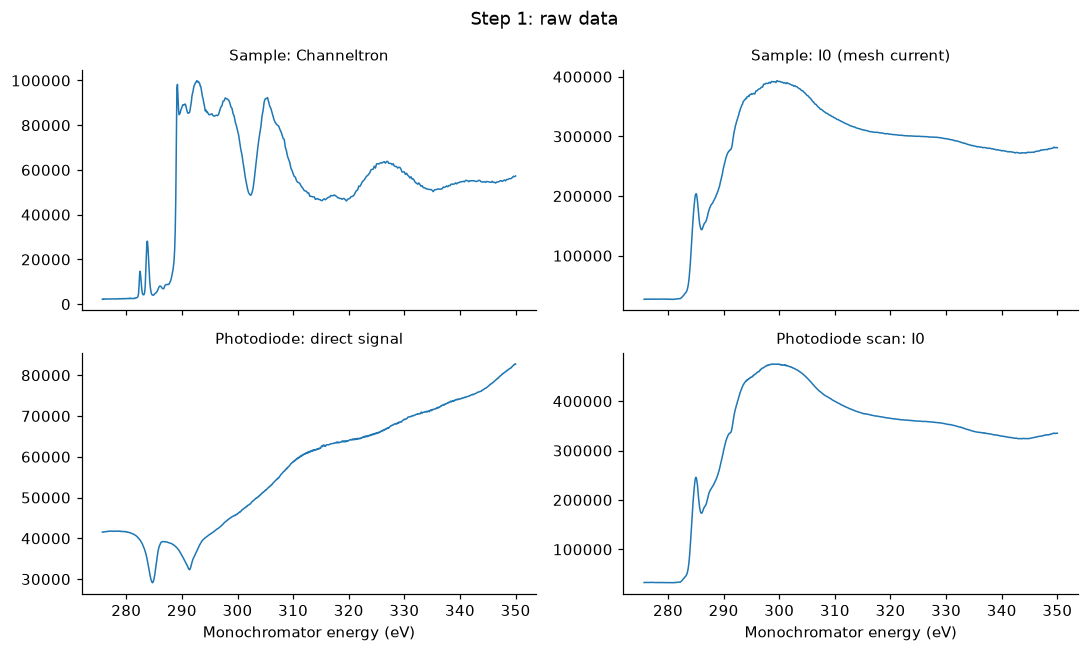

In [3]:
E = "Monochromator Energy"
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
panels = [
    (axes[0, 0], sample_raw, "Channeltron", "Sample: Channeltron"),
    (axes[0, 1], sample_raw, "I zero", "Sample: I0 (mesh current)"),
    (axes[1, 0], photodiode_raw, "Direct_PHD_VF", "Photodiode: direct signal"),
    (axes[1, 1], photodiode_raw, "I zero", "Photodiode scan: I0"),
]
for ax, df, col, title in panels:
    ax.plot(df[E], df[col], lw=1)
    ax.set_title(title, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Monochromator energy (eV)")
fig.suptitle("Step 1: raw data")
fig.tight_layout()
save(fig, "01_raw_data.png")

## 2. Energy calibration

`energy_correct` finds the reference-foil peak inside the search window (smoothed, with a sub-grid quadratic fit) and shifts the energy axis so the peak sits at 285 eV. Sample and photodiode scans are calibrated independently.

In [4]:
calibration = EnergyCalibration()
sample_cal = energy_correct(sample_raw, calibration)
photodiode_cal = energy_correct(photodiode_raw, calibration)

shift = (sample_cal["Corrected Energy"] - sample_cal[E])[0]
print(f"Sample energy shift: {shift:+.3f} eV")

Sample energy shift: -0.033 eV


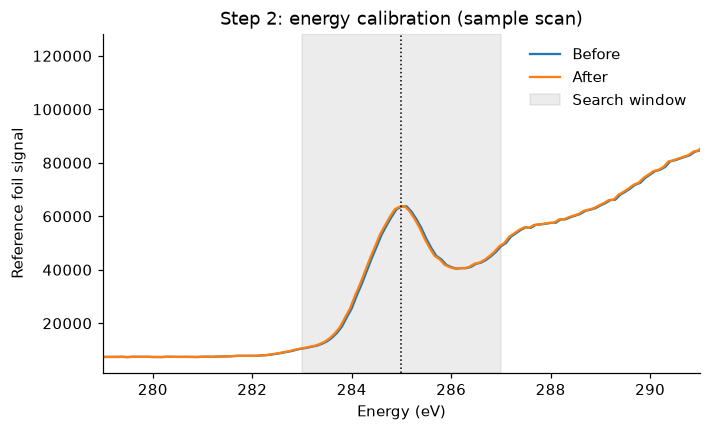

In [5]:
lo, hi = calibration.search_window_eV
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sample_cal[E], sample_cal["Reference Foil VF"], label="Before")
ax.plot(sample_cal["Corrected Energy"], sample_cal["Reference Foil VF"], label="After")
ax.axvspan(lo, hi, color="grey", alpha=0.15, label="Search window")
ax.axvline(calibration.calibrated_energy_eV, color="k", ls=":", lw=1)
ax.set_xlim(lo - 4, hi + 4)
ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Reference foil signal")
ax.set_title("Step 2: energy calibration (sample scan)")
ax.legend(frameon=False)
save(fig, "02_energy_calibration.png")

## 3. Normalise to I0 and divide by the photodiode

The sample's Channeltron signal is divided by its I0, then by the I0-normalised photodiode scan (interpolated onto the sample's energy axis). This removes the beamline transmission function.

In [6]:
result = double_normalise(SAMPLE, PHOTODIODE)
result.columns

['index',
 'Energy Setpoint [eV]',
 'unchanging value, maybe energy steps',
 'Monochromator Energy',
 'Drain Current VF [eV]',
 'I zero',
 'Reference Foil VF',
 'MCP?',
 'Channeltron',
 'Direct_PHD_VF',
 'TFY_PHD_VF',
 'Drain Current (Keithley1)',
 'I zero (Keithley 3)',
 'Reference Foil (Keithley4)',
 'Keithly6',
 'Beam Current [mA]',
 'BL_PHD_VF',
 'BL_PHD_Keithley2',
 'Gap Request, mm',
 '20  [1-D Detector  17]  SR14ID01:GAP_MONITOR, , mm',
 '  21  [1-D Detector  18]  SR14ID01IOC68:IP330_1.VAL, , ',
 '-0.0105287256',
 'Corrected Energy',
 'Sample/I0',
 'Photodiode/I0',
 'Corrected',
 'Background Fit',
 'Background subtracted',
 'Step Scaled',
 'Step Scaled Error']

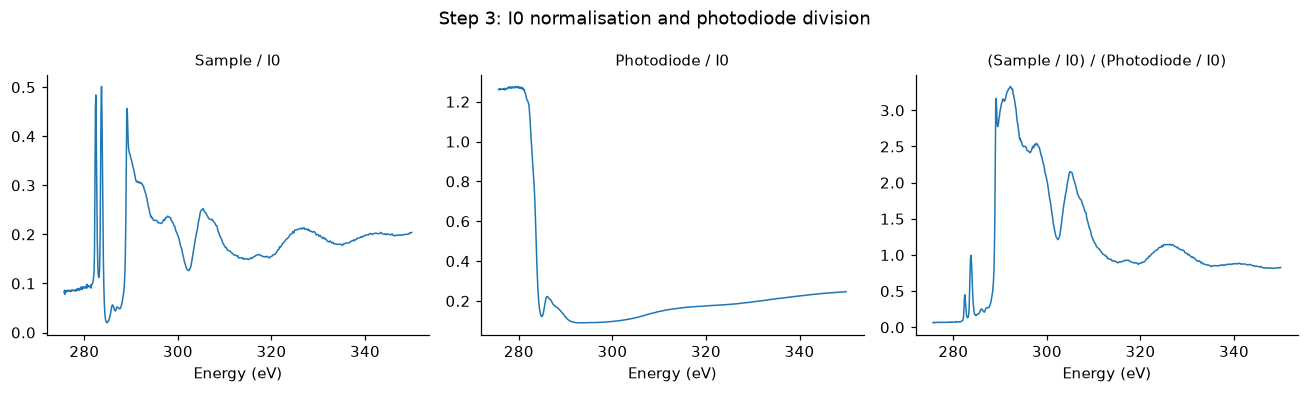

In [7]:
X = "Corrected Energy"
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
for ax, col, title in zip(
    axes,
    ["Sample/I0", "Photodiode/I0", "Corrected"],
    ["Sample / I0", "Photodiode / I0", "(Sample / I0) / (Photodiode / I0)"],
):
    ax.plot(result[X], result[col], lw=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Energy (eV)")
fig.suptitle("Step 3: I0 normalisation and photodiode division")
fig.tight_layout()
save(fig, "03_photodiode_normalisation.png")

## 4. Pre-edge background subtraction

A straight line is fitted over the pre-edge window (`BackgroundFit.fit_window_eV`) and subtracted.

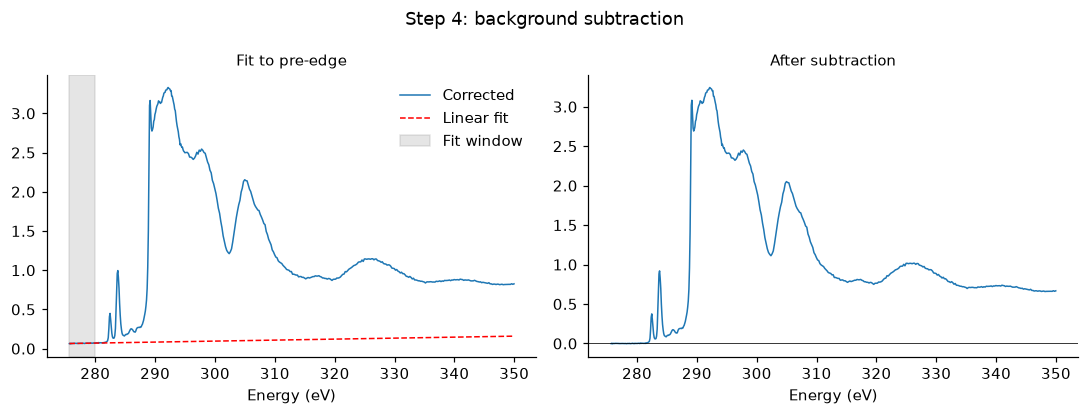

In [8]:
bg = BackgroundFit()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
axes[0].plot(result[X], result["Corrected"], lw=1, label="Corrected")
axes[0].plot(result[X], result["Background Fit"], "r--", lw=1, label="Linear fit")
axes[0].axvspan(*bg.fit_window_eV, color="grey", alpha=0.2, label="Fit window")
axes[0].set_title("Fit to pre-edge", fontsize=10)
axes[0].legend(frameon=False)
axes[1].plot(result[X], result["Background subtracted"], lw=1)
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_title("After subtraction", fontsize=10)
for ax in axes:
    ax.set_xlabel("Energy (eV)")
fig.suptitle("Step 4: background subtraction")
fig.tight_layout()
save(fig, "04_background_subtraction.png")

## 5. Step-edge normalisation

The spectrum is divided by its mean over the post-edge window (`StepNormalisation.window_eV`), so the edge jump is one. The shaded band is the 1-sigma uncertainty propagated from Poisson counting statistics.

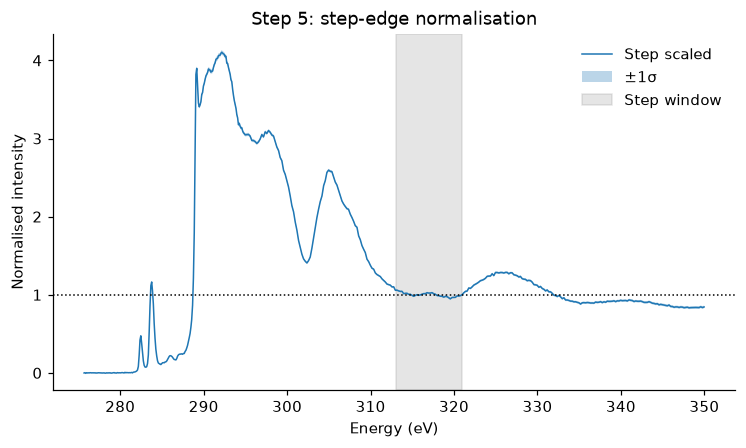

In [9]:
step = StepNormalisation()
y, err = result["Step Scaled"].to_numpy(), result["Step Scaled Error"].to_numpy()
x = result[X].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x, y, lw=1, label="Step scaled")
ax.fill_between(x, y - err, y + err, alpha=0.3, label="±1σ")
ax.axvspan(*step.window_eV, color="grey", alpha=0.2, label="Step window")
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Normalised intensity")
ax.set_title("Step 5: step-edge normalisation")
ax.legend(frameon=False)
save(fig, "05_step_normalisation.png")

## Summary of all stages

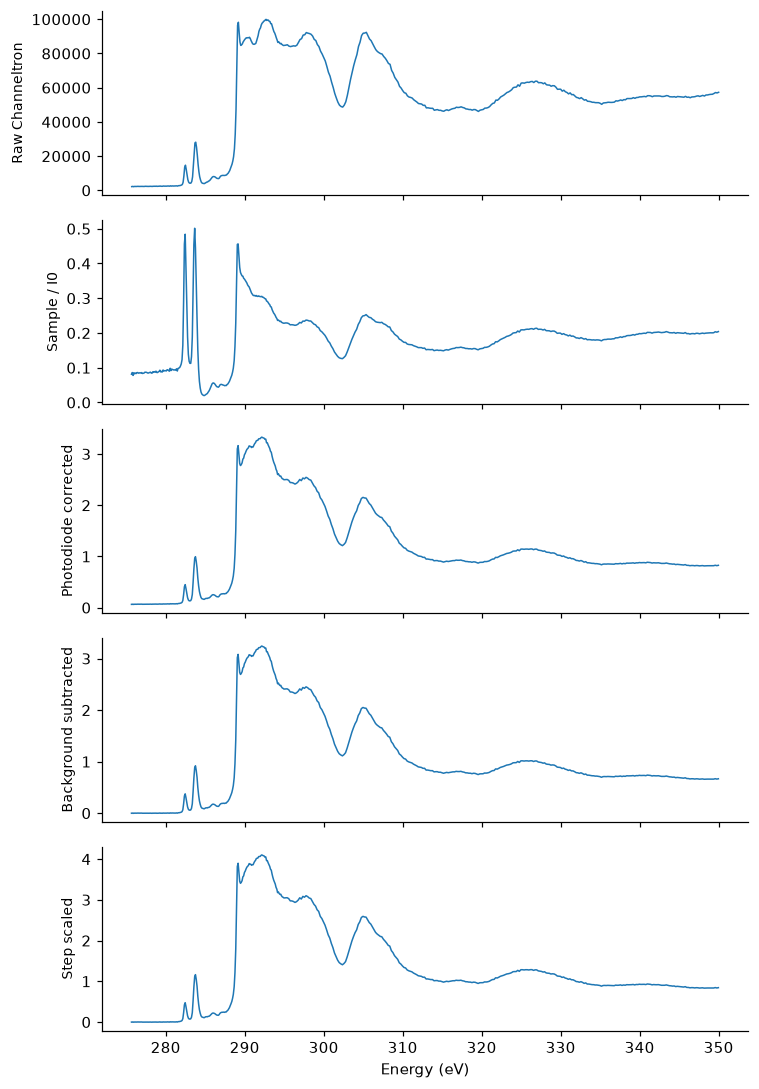

In [10]:
stages = [
    ("Channeltron", sample_cal, E, "Raw Channeltron"),
    ("Sample/I0", result, X, "Sample / I0"),
    ("Corrected", result, X, "Photodiode corrected"),
    ("Background subtracted", result, X, "Background subtracted"),
    ("Step Scaled", result, X, "Step scaled"),
]
fig, axes = plt.subplots(len(stages), 1, figsize=(7, 10), sharex=True)
for ax, (col, df, xcol, label) in zip(axes, stages):
    ax.plot(df[xcol], df[col], lw=1)
    ax.set_ylabel(label, fontsize=9)
axes[-1].set_xlabel("Energy (eV)")
fig.tight_layout()
save(fig, "06_all_stages.png")

## Overriding the defaults

Every energy window is a field on a config dataclass; pass only what you want to change.

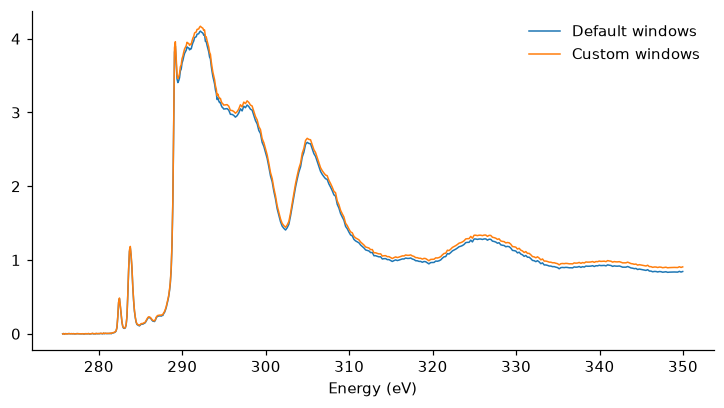

In [11]:
custom = double_normalise(
    SAMPLE,
    PHOTODIODE,
    background=BackgroundFit(fit_window_eV=(276.0, 279.0)),
    step_normalisation=StepNormalisation(window_eV=(330.0, 340.0)),
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(result[X], result["Step Scaled"], lw=1, label="Default windows")
ax.plot(custom[X], custom["Step Scaled"], lw=1, label="Custom windows")
ax.set_xlabel("Energy (eV)")
ax.legend(frameon=False)